# TP1 Modelisation

## Partie 1

### Imports

In [4]:
import os
os.environ["KERAS_BACKEND"] = "torch"
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers
from keras import Sequential
from keras.optimizers import SGD

### 1.2. Implémentation des couches de neurones

In [5]:
# Architecture du réseau
modele = Sequential()
# Couches de neurones
modele.add(layers.Input(shape=(1,)))
modele.add(layers.Dense(2, activation="relu"))
modele.add(layers.Dense(1, activation="relu"))
# Pour vérifier l'achitecture du réseau
modele.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 2)              │             4 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7 (28.00 B)

 Trainable params: 7 (28.00 B)

 Non-trainable params: 0 (0.00 B)

### 1.3. Affectation des poids

In [7]:
import numpy as np
# Couche 0 (1->2)
coeff = np.array([[1., -0.5]]) # (1, 2)
biais = np.array([-1, 1]) # (2,)
modele.layers[0].set_weights([coeff, biais])

In [8]:
# Poids de la deuxième couche (2->1)
coeff2 = np.array([[1], [1]]) # (2, 1)
biais2 = np.array([0]) # (1,)
modele.layers[1].set_weights([coeff2, biais2])

In [9]:
print(modele.layers[0].get_weights())

[array([[ 1. , -0.5]], dtype=float32), array([-1.,  1.], dtype=float32)]


### 1.4. Évaluation par le réseau d’une entrée

In [10]:
entree = np.array([[3.0]])
sortie = modele.predict(entree)
print(sortie)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
[[2.]]


### 1.5. Visualisation

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


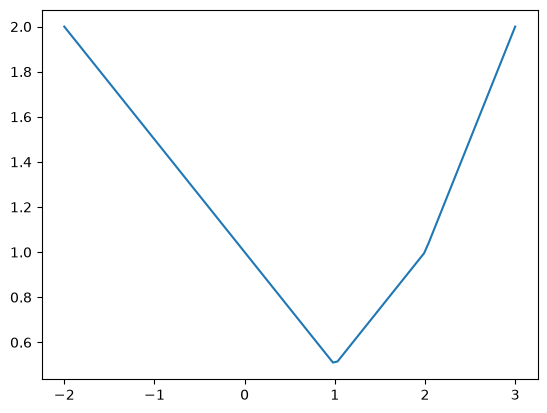

In [12]:
import matplotlib.pyplot as plt
liste_x = np.linspace(-2, 3, num=100)
entree = np.array([[x] for x in liste_x])
sortie = modele.predict(entree)

liste_y = np.array([y[0] for y in sortie])
plt.plot(liste_x,liste_y)
plt.show()

### 1.6. A vous !

In [21]:
# Architecture du réseau
modele = Sequential()
# Couches de neurones
modele.add(layers.Input(shape=(2,)))
modele.add(layers.Dense(3, activation="sigmoid"))
modele.add(layers.Dense(1, activation="sigmoid"))
modele.summary()

# Couche 0 (1->2)
coeff = np.array([[1., 3., -5.],[2.,-4.,-6.]]) 
biais = np.array([-1, 0, 1]) 
modele.layers[0].set_weights([coeff, biais])
print(modele.layers[0].get_weights())

# Poids de la deuxième couche (2->1)
coeff2 = np.array([[1], [1], [1]]) # (3, 1)
biais2 = np.array([-3]) # (1,)
modele.layers[1].set_weights([coeff2, biais2])
print(modele.layers[1].get_weights())

entree = np.array([[7.0, -5.0]])
sortie = modele.predict(entree)
print(sortie)
entree = np.array([[1, -1]])
sortie = modele.predict(entree)
print(sortie)


Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_18 (Dense)                │ (None, 3)              │             9 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 1)              │             4 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13 (52.00 B)

 Trainable params: 13 (52.00 B)

 Non-trainable params: 0 (0.00 B)

[array([[ 1.,  3., -5.],
       [ 2., -4., -6.]], dtype=float32), array([-1.,  0.,  1.], dtype=float32)]
[array([[1.],
       [1.],
       [1.]], dtype=float32), array([-3.], dtype=float32)]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
[[0.12303182]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
[[0.26876235]]


13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


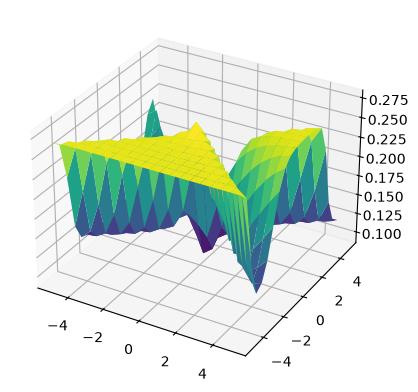

In [22]:
# --- Visualisation 3D du modèle ---
# Création d'une grille de valeurs pour les axes X et Y
VX = np.linspace(-5, 5, 20)
VY = np.linspace(-5, 5, 20)
# Construction du maillage 2D (toutes les combinaisons X, Y)
X, Y = np.meshgrid(VX, VY)
# Préparation des données d'entrée pour le modèle (couples x, y)
entree = np.c_[X.ravel(), Y.ravel()]
# Prédiction du modèle sur chaque point de la grille
Z=modele.predict(entree).reshape(X.shape)
# Création de la figure 3D
fig = plt.figure()
ax = plt.axes(projection='3d')
# Tracé de la surface prédite
ax.plot_surface(X, Y, Z, cmap='viridis')
# Affichage du graphique
plt.show()

## 2. Approximation d’une fonction à une variable

### 2.1. Données

## 2.2 Programme

Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_45 (Dense)                │ (None, 10)             │            20 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_46 (Dense)                │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_47 (Dense)                │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_48 (Dense)                │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_49 (Dense)                │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 361 (1.41 KB)

 Trainable params: 361 (1.41 KB)

 Non-trainable params: 0 (0.00 B)

None
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


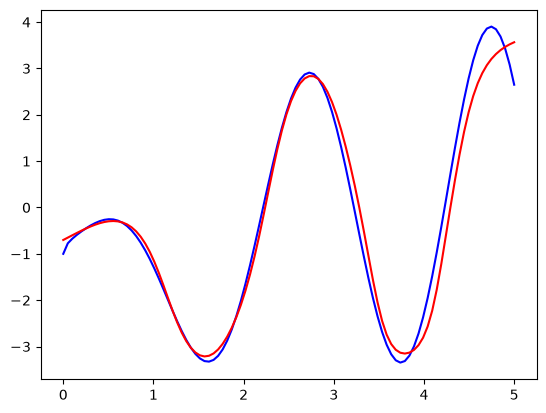

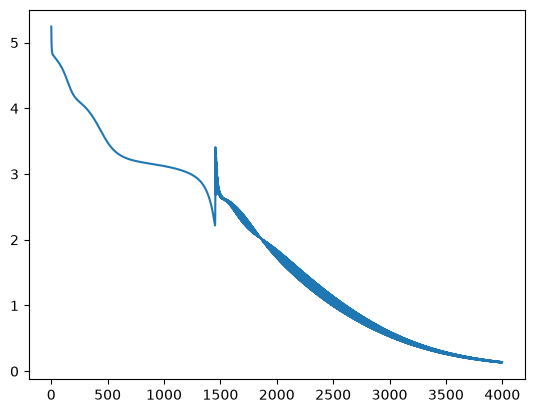

In [29]:
# Partie A. Données
keras.utils.set_random_seed(42) # pour reproductibilité
# Fonction à approcher
def f(x):
    return np.cos(2*x) + x*np.sin(3*x) + x**0.5 - 2
a, b = 0, 5 # intervalle [a,b]
N = 100 # volume de données
X = np.linspace(a, b, N) # abscisses
Y = f(X) # ordonnées
# transforme X en une colonne, comportant le bon nombre de ligne (i.e. "-1"), idem pour Y
X_train = X.reshape(-1,1)
Y_train = Y.reshape(-1,1)
# Partie B. Réseau
# Modèle : 1 entrée -> 4 couches tanh, p neurones par couche, 1 sortie linéaire
p = 10
modele = Sequential([
    layers.Input(shape=(1,)),
    layers.Dense(p, activation='tanh'),
    layers.Dense(p, activation='tanh'),
    layers.Dense(p, activation='tanh'),
    layers.Dense(p, activation='tanh'),
    layers.Dense(1, activation='linear'), # linear par défaut, mais on explicite
])
# --- Compilation : ici on choisit la fonction d'erreur, la méthode d'optimisation
# et on initialise (aléatoirement) les praramètres
modele.compile(loss='mean_squared_error',optimizer=SGD(learning_rate=0.01))
# SGD : "Stochastic gradient descent"
# --- Résumé ---
print(modele.summary())
#Entraînement du modèle ; verbose=1 affiche la progression et la loss à chaque epoch
history = modele.fit(X_train, Y_train, epochs=4000, batch_size=len(X_train), verbose=0)
# Attention ici comme batch_size=len(X_train) c'est une descente de gradient classique
# (non stochastique) : optimizer=SGD(learning_rate=0.01)
# sert uniquement à fixer le taux d'apprentissage.
# Affichage de la fonction et de son approximation :
# A exécuter sur une cellule indépendante
Y_predict = modele.predict(X_train) # calcul de la prédiction
plt.plot(X_train, Y_train, color='blue')
plt.plot(X_train, Y_predict, color='red')
plt.show()
# Affichage de l'erreur au fil des époques
plt.plot(history.history['loss'])
plt.show()

## 3. Exercices 

### Exercice 2

In [30]:
# Construction explicite : deux couches cachees
keras.utils.set_random_seed(42)
p = 5
modele = Sequential([
layers.Input(shape=(1,)),
layers.Dense(p, activation="tanh"),
layers.Dense(p, activation="tanh"),
layers.Dense(1, activation="linear")
])
modele.compile(
optimizer=keras.optimizers.Adam(learning_rate=0.01),
loss="mean_squared_error"
)
# Apprentissage (a placer dans une cellule distincte)
history = modele.fit(
X_train, Y_train, epochs=1000,
batch_size=len(X_train), verbose=0
)